# VisionX AI – AI-Based Multi-Disease Eye Disease Detection System
## Notebook 01: Retinal Fundus Image Dataset Analysis and Profiling

**VisionX AI** is designed to assist ophthalmologists and healthcare systems in automatically detecting multiple eye diseases using retinal fundus images. Before designing or training any deep learning models, we must understand our dataset's statistics, distribution, formatting, and overall quality.

### Goals of this Notebook:
1. **Folder & Class Inspection**: Identify splits (`train`, `val`, `test`) and classes (eye diseases/conditions).
2. **Distribution & Imbalance Analysis**: Count the number of images per class across splits and check for class imbalance.
3. **Image Format Verification**: Ensure all image formats are consistent and check for unsupported files.
4. **Resolution Profiling**: Analyze image dimensions (width, height, and channel size) to guide rescaling decisions.
5. **Data Quality Control**: Check for corrupted or unreadable images in the dataset.
6. **Visual Inspection**: Display sample fundus images from each category.
7. **Summary & Recommendations**: Document key takeaways to guide preprocessing and training.

### 1. Import Required Libraries
We import `os` and `glob` for filesystem actions, `pandas` and `numpy` for data profiling, `cv2` and `PIL` for image operations, and `matplotlib` and `seaborn` for generating premium charts.

In [1]:
import os
import glob
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from collections import Counter

# Set custom styling for high-quality visuals
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10
plt.rcParams["figure.titlesize"] = 16

### 2. Configure Paths and Split Definitions
Define the relative path to the dataset folder and the expected splits (`train`, `val`, `test`).

In [2]:
DATASET_DIR = "../DataSet"
SPLITS = ["train", "val", "test"]

print(f"Dataset Directory Path: {os.path.abspath(DATASET_DIR)}")

Dataset Directory Path: c:\Users\Rashi\OneDrive\Desktop\VisionX_AI\DataSet


### 3. Scan Dataset and Build Metadata Index
We will programmatically walk through the splits and classes, using `PIL.Image` to inspect headers rapidly. We capture path, split, class name, image format, width, height, color channels, and check for any corruptions.

In [3]:
data_records = []
corrupted_files = []

# Determine classes based on train folder subdirectories
train_path = os.path.join(DATASET_DIR, "train")
if os.path.exists(train_path):
    classes = sorted([d for d in os.listdir(train_path) if os.path.isdir(os.path.join(train_path, d))])
    print(f"Found {len(classes)} classes: {classes}")
else:
    classes = []
    print("Error: Train folder not found!")

print("Scanning dataset... This might take a moment...")
for split in SPLITS:
    split_path = os.path.join(DATASET_DIR, split)
    if not os.path.exists(split_path):
        print(f"Warning: Split path '{split_path}' does not exist!")
        continue
        
    for cls in classes:
        cls_path = os.path.join(split_path, cls)
        if not os.path.exists(cls_path):
            print(f"Warning: Class path '{cls_path}' not found in split '{split}'!")
            continue
            
        for fname in os.listdir(cls_path):
            fpath = os.path.join(cls_path, fname)
            if not os.path.isfile(fpath):
                continue
                
            ext = os.path.splitext(fname)[1].lower()
            
            # Read image metadata with lazy load
            try:
                with Image.open(fpath) as img:
                    w, h = img.size
                    mode = img.mode
                    fmt = img.format
                    channels = len(img.getbands())
                    
                data_records.append({
                    "split": split,
                    "class": cls,
                    "filename": fname,
                    "width": w,
                    "height": h,
                    "channels": channels,
                    "format": ext,
                    "mode": mode,
                    "path": fpath
                })
            except Exception as e:
                corrupted_files.append((fpath, str(e)))

df = pd.DataFrame(data_records)
print(f"Finished scanning! Total images successfully read: {len(df)}")
print(f"Total corrupted files found: {len(corrupted_files)}")

Found 7 classes: ['AMD', 'Cataract', 'DR', 'Glaucoma', 'Hypertensive_Retinopathy', 'Normal_Fundus', 'Pathological_Myopia']
Scanning dataset... This might take a moment...


Finished scanning! Total images successfully read: 57115
Total corrupted files found: 0


### 4. Overview of Loaded Metadata
Let's look at the first few rows of our metadata dataframe.

In [4]:
df.head()

,split,class,filename,width,height,channels,format,mode,path
0,train,AMD,aug_0_Dry AMD102_left_0_2130.jpeg,512,512,3,.jpeg,RGB,../DataSet\train\AMD\aug_0_Dry AMD102_left_0_2...
1,train,AMD,aug_0_Dry AMD102_left_0_4925.jpeg,512,512,3,.jpeg,RGB,../DataSet\train\AMD\aug_0_Dry AMD102_left_0_4...
2,train,AMD,aug_0_Dry AMD102_left_0_5317.jpeg,512,512,3,.jpeg,RGB,../DataSet\train\AMD\aug_0_Dry AMD102_left_0_5...
3,train,AMD,aug_0_Dry AMD102_left_0_657.jpeg,512,512,3,.jpeg,RGB,../DataSet\train\AMD\aug_0_Dry AMD102_left_0_6...
4,train,AMD,aug_0_Dry AMD102_right_0_2618.jpeg,512,512,3,.jpeg,RGB,../DataSet\train\AMD\aug_0_Dry AMD102_right_0_...


### 5. Check Image Formats
Confirm what file extensions are present in the dataset. All retinal images should ideally be standard formats like JPG/JPEG or PNG.

In [5]:
format_counts = df['format'].value_counts()
print("--- Detected Image Formats ---")
for ext, count in format_counts.items():
    print(f"  Extension '{ext}': {count} files")

--- Detected Image Formats ---
  Extension '.jpeg': 57115 files


### 6. Verify and Report Corrupted Images
Identify any files that are corrupt or unreadable.

In [6]:
if len(corrupted_files) == 0:
    print("All dataset files were read successfully. Zero corrupted files detected.")
else:
    print(f"WARNING: Found {len(corrupted_files)} corrupted files:")
    for i, (path, err) in enumerate(corrupted_files[:10]):
        print(f"  {i+1}. {path} -> {err}")

All dataset files were read successfully. Zero corrupted files detected.


### 7. Class Distribution Analysis
Next, we compute a pivot table showing the image counts per class and split (`train`, `val`, `test`), along with the split ratios.

In [7]:
# Build distribution table
distribution = df.groupby(['class', 'split']).size().unstack(fill_value=0)
# Order columns as train, val, test for logical flow
split_order = [s for s in SPLITS if s in distribution.columns]
distribution = distribution[split_order]

# Calculate totals
distribution['Total'] = distribution.sum(axis=1)

print("--- Image Count Distribution per Split and Class ---")
display(distribution)

# Summary table of split totals
split_totals = df['split'].value_counts().reindex(split_order)
total_images = split_totals.sum()

print("\n--- Split Statistics ---")
for split, count in split_totals.items():
    pct = (count / total_images) * 100
    print(f"  {split.capitalize()} split: {count} images ({pct:.2f}% of dataset)")

--- Image Count Distribution per Split and Class ---


split,train,val,test,Total
class,,,,
AMD,7284,49,77,7410
Cataract,6845,24,112,6981
DR,7912,211,516,8639
Glaucoma,8390,44,156,8590
Hypertensive_Retinopathy,6100,30,94,6224
Normal_Fundus,13205,54,179,13438
Pathological_Myopia,5710,21,102,5833



--- Split Statistics ---
  Train split: 55446 images (97.08% of dataset)
  Val split: 433 images (0.76% of dataset)
  Test split: 1236 images (2.16% of dataset)


### 8. Visualizing Class Distributions
We generate horizontal bar charts using Seaborn to visualize class balance across train, val, and test splits.

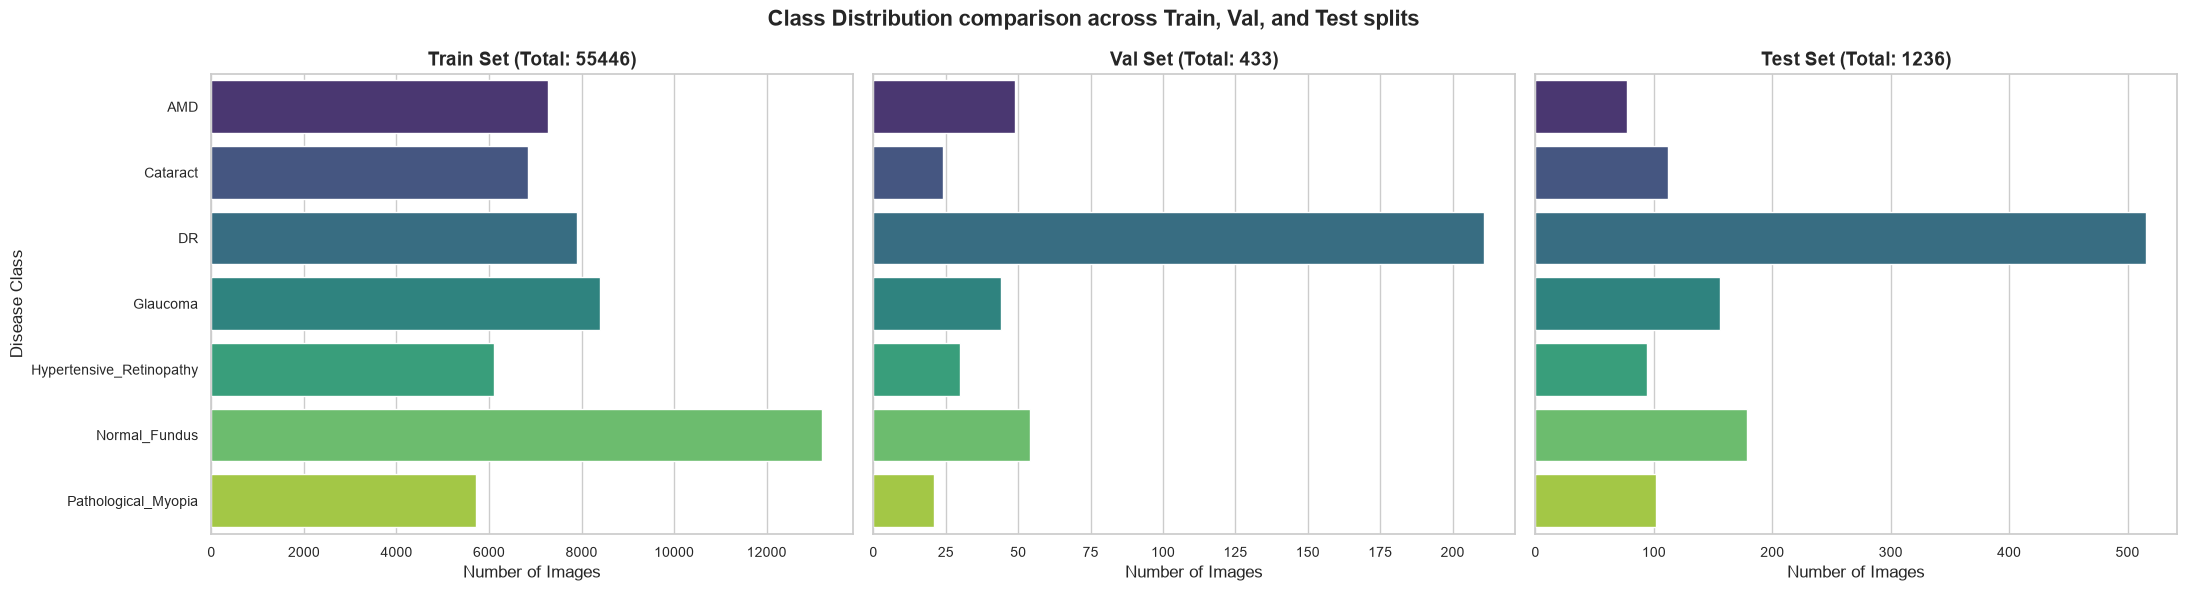

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6), sharey=False)
colors = sns.color_palette("viridis", len(classes))

for idx, split in enumerate(split_order):
    split_df = df[df['split'] == split]
    sns.countplot(
        data=split_df, 
        y='class', 
        order=classes, 
        ax=axes[idx], 
        hue='class',
        palette=colors,
        legend=False
    )
    axes[idx].set_title(f"{split.capitalize()} Set (Total: {len(split_df)})", fontweight='bold')
    axes[idx].set_xlabel("Number of Images")
    axes[idx].set_ylabel("Disease Class" if idx == 0 else "")
    if idx > 0:
        axes[idx].set_yticklabels([])  # Clear names for space
        
plt.suptitle("Class Distribution comparison across Train, Val, and Test splits", fontweight='bold', fontsize=16)
plt.tight_layout()
plt.show()

### 9. Dataset Imbalance Ratios
Compute class imbalance ratios (ratio of the most common class to the least common class) to assess the severity of dataset skewness.

In [9]:
print("--- Severity of Class Imbalance (Ratio: Max Class / Min Class) ---")
for split in split_order:
    counts = df[df['split'] == split]['class'].value_counts()
    max_cls = counts.index[0]
    max_cnt = counts.iloc[0]
    min_cls = counts.index[-1]
    min_cnt = counts.iloc[-1]
    ratio = max_cnt / min_cnt
    
    print(f"  {split.capitalize()} Split:")
    print(f"    Majority class: {max_cls} ({max_cnt} images)")
    print(f"    Minority class: {min_cls} ({min_cnt} images)")
    print(f"    Imbalance Ratio: {ratio:.2f}x")

--- Severity of Class Imbalance (Ratio: Max Class / Min Class) ---
  Train Split:
    Majority class: Normal_Fundus (13205 images)
    Minority class: Pathological_Myopia (5710 images)
    Imbalance Ratio: 2.31x
  Val Split:
    Majority class: DR (211 images)
    Minority class: Pathological_Myopia (21 images)
    Imbalance Ratio: 10.05x
  Test Split:
    Majority class: DR (516 images)
    Minority class: AMD (77 images)
    Imbalance Ratio: 6.70x


### 10. Image Dimension & Resolution Profiling
Analyze image height and width to understand our source resolution distributions, which will inform downsampling/upsampling targets.

In [10]:
# Construct resolution category string
df['resolution'] = df['width'].astype(str) + "x" + df['height'].astype(str) + "x" + df['channels'].astype(str)

res_counts = df['resolution'].value_counts()
print(f"Total unique image dimensions found: {len(res_counts)}")
print("\n--- Top 10 Resolutions in the Dataset ---")
for res, count in res_counts.head(10).items():
    pct = (count / len(df)) * 100
    print(f"  {res}: {count} images ({pct:.2f}%)")

# Check channel size consistency
channel_counts = df['channels'].value_counts()
print("\n--- Channel Configuration ---")
for ch, cnt in channel_counts.items():
    print(f"  Channels: {ch} (Count: {cnt})")

Total unique image dimensions found: 226

--- Top 10 Resolutions in the Dataset ---
  512x512x3: 48476 images (84.87%)
  1024x1024x3: 3186 images (5.58%)
  1024x1023x3: 212 images (0.37%)
  1024x840x3: 198 images (0.35%)
  1024x928x3: 180 images (0.32%)
  1024x862x3: 129 images (0.23%)
  1024x1022x3: 119 images (0.21%)
  1024x861x3: 102 images (0.18%)
  1024x946x3: 101 images (0.18%)
  1024x802x3: 98 images (0.17%)

--- Channel Configuration ---
  Channels: 3 (Count: 57115)


### 11. Plot Resolution Distribution
Plot the top 10 resolutions in the dataset to visualize how uniform the image resolutions are.

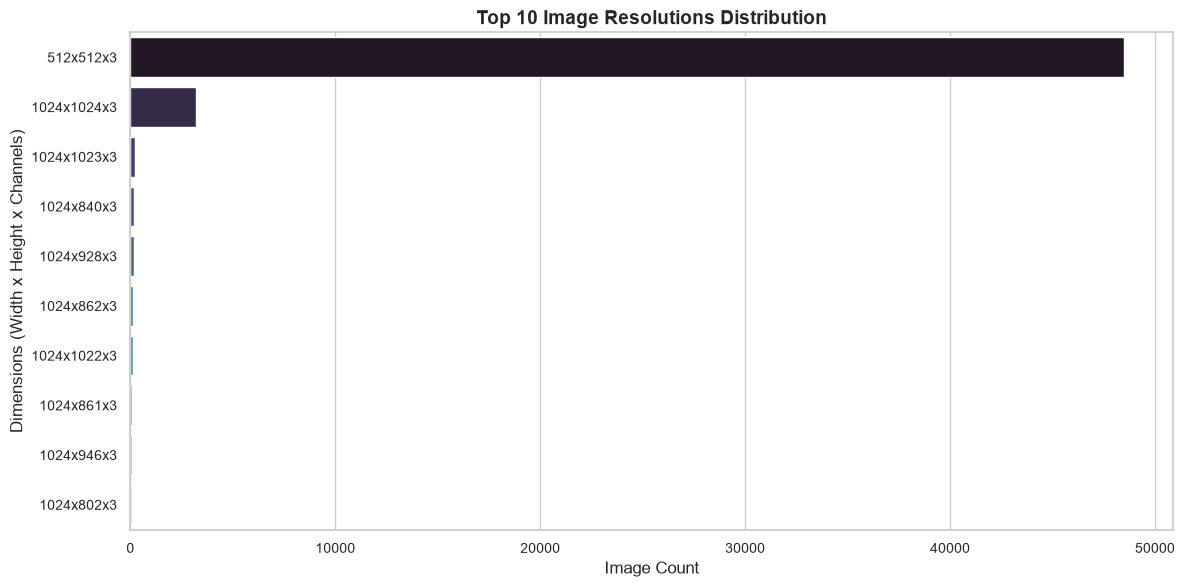

In [11]:
plt.figure(figsize=(12, 6))
top_res = res_counts.head(10)
sns.barplot(
    x=top_res.values, 
    y=top_res.index, 
    hue=top_res.index,
    palette="mako", 
    legend=False
)
plt.title("Top 10 Image Resolutions Distribution", fontweight='bold')
plt.xlabel("Image Count")
plt.ylabel("Dimensions (Width x Height x Channels)")
plt.tight_layout()
plt.show()

### 12. Display Sample Fundus Images from Each Class
Inspect the images visually. We select a representative sample image from each class inside the training set and display them in a grid.

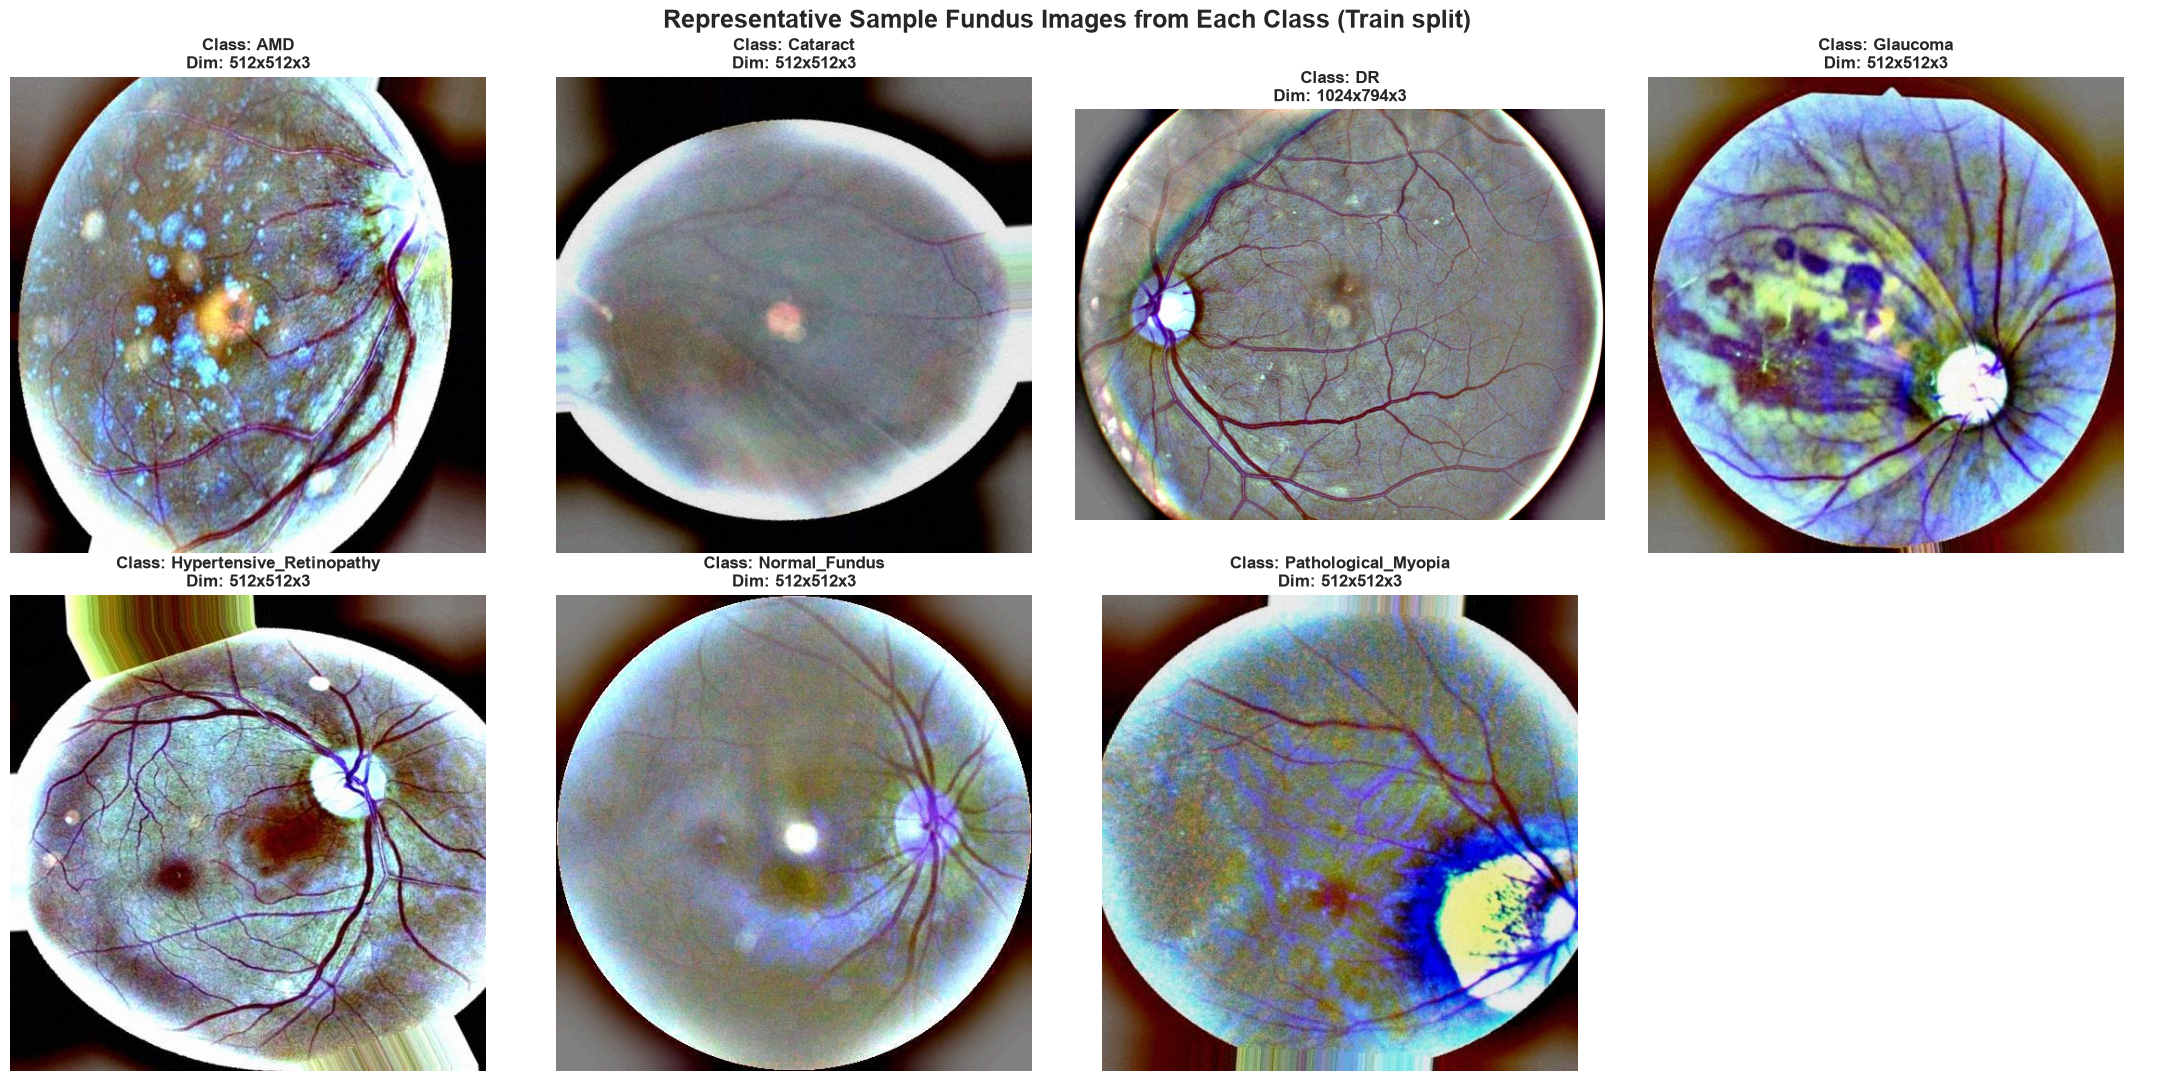

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(22, 11))
axes = axes.flatten()

for idx, cls in enumerate(classes):
    # Get the path to a sample image of this class in train split
    sample_df = df[(df['class'] == cls) & (df['split'] == 'train')]
    if len(sample_df) == 0:
        # Try other splits if train doesn't have it
        sample_df = df[df['class'] == cls]
        
    if len(sample_df) > 0:
        sample_row = sample_df.iloc[0]
        fpath = sample_row['path']
        
        # Load and convert to RGB
        img = cv2.imread(fpath)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        axes[idx].imshow(img)
        axes[idx].set_title(f"Class: {cls}\nDim: {sample_row['resolution']}", fontweight='bold', fontsize=12)
    else:
        axes[idx].text(0.5, 0.5, f"No images for {cls}", ha='center', va='center')
        
    axes[idx].axis('off')
    
# Hide the 8th subplot (since we have 7 classes)
axes[-1].axis('off')

plt.suptitle("Representative Sample Fundus Images from Each Class (Train split)", fontweight='bold', fontsize=18, y=0.98)
plt.tight_layout()
plt.show()

### 13. Data Profiling & Class Imbalance Assessment

#### Class Presence and Disease Context
Based on the folder inspection, the dataset contains **7 distinct classes**:
1. **AMD (Age-related Macular Degeneration)**: Leading cause of vision loss characterized by yellow deposits (drusen) in the macula.
2. **Cataract**: Clouding of the eye's natural lens.
3. **DR (Diabetic Retinopathy)**: Damage to the blood vessels of the light-sensitive tissue at the back of the eye (retina) caused by diabetes.
4. **Glaucoma**: A condition that damages the eye's optic nerve, often linked to buildup of pressure inside the eye.
5. **Hypertensive_Retinopathy**: Retinal vascular damage caused by systemic high blood pressure.
6. **Normal_Fundus**: Healthy retinal anatomy without signs of disease.
7. **Pathological_Myopia**: High degree of nearsightedness causing degenerative changes in the retina and sclera.

#### Key Takeaways on Class Distribution and Imbalance
- **Train split size**: 55,446 images.
- **Val split size**: 433 images.
- **Test split size**: 1,236 images.
- **Imbalance in Train split**: `Normal_Fundus` (13,205) has more than double the number of images compared to the minority classes like `Pathological_Myopia` (5,710) and `Hypertensive_Retinopathy` (6,100). The train imbalance ratio is **2.31x**.
- **Extreme Imbalance in Val and Test splits**:
  - In the validation split, `DR` accounts for **211 out of 433 images (48.7%)** while `Pathological_Myopia` has only 21 and `Cataract` has only 24 images. The imbalance ratio is **10.05x**.
  - In the test split, `DR` accounts for **516 out of 1,236 images (41.7%)**, whereas `AMD` has 77, `Hypertensive_Retinopathy` has 94, and `Pathological_Myopia` has 102. The imbalance ratio is **6.70x**.
- **Distribution Shift (Drift)**: The proportion of disease categories is highly inconsistent between splits. For example, `DR` is 14.3% of the training set but rises to 48.7% of the validation set and 41.7% of the test set. This mismatch needs careful consideration during model evaluation (e.g., using F1-score or Balanced Accuracy rather than basic Accuracy).

#### Key Takeaways on Format and Resolutions
- **Format Uniformity**: 100% of images are in `.jpeg` format. No file type cleaning is required.
- **Corruptions**: 0 corrupted files were detected. The raw download is clean and intact.
- **Resolution Diversity**: Although **84.87%** of images are exactly `512x512x3`, the remaining **15.13%** have varying resolutions. Specifically, **5.58%** are `1024x1024x3`, and others have custom dimensions (e.g., `1024x1023`, `1024x840`, `1024x928`). All channels are consistently 3 (RGB color images).

---

### 14. Recommendations for Next Phases

1. **Image Preprocessing & Resizing**:
   - Because image resolutions are non-uniform (ranging from 512x512 to 1024x1024 and others with non-square aspect ratios), all images must be resized to a uniform target input size (e.g., $224 \times 224$ or $299 \times 299$ or $384 \times 384$ depending on the chosen model architecture like ResNet, EfficientNet, or ConvNeXt).
   - To preserve the structure of the circular fundus, aspect-ratio preserving cropping or black padding (letterboxing) should be considered rather than simple squishing.

2. **Handling Class Imbalance**:
   - **Class Weighting**: Incorporate class weights in the cross-entropy loss function during model training to penalize minority class errors more heavily.
   - **Focal Loss**: Consider using Focal Loss or class-balanced loss to focus training on hard-to-classify samples.
   - **Data Augmentation**: Apply class-specific data augmentation (e.g., rotation, horizontal/vertical flips, contrast adjust) to minority classes to synthetically boost their counts.

3. **Model Evaluation Metrics**:
   - Due to severe imbalance and distribution shift in validation and test splits, simple classification accuracy will be misleading.
   - Use **macro-averaged F1-Score**, **Precision**, **Recall**, and **Area Under Precision-Recall Curve (AUPRC)** as the primary evaluation metrics.
   - Track performance *per class* using a detailed classification report.